# State-Conditioned Limit-Order Execution

All reusable logic lives in **`order_execution.py`** (engine) and **`oe_plots.py`** (figures).
This notebook only configures runs and renders results, so the full study reruns for any of the
seven assets in one call.

**Pipeline (no-leakage):** `load_data -> build_ohlc -> compute_ranges -> compute_ewma_states ->`
`generate_signals -> restrict_to_ai_overlap -> build_epdf (in-sample only) ->`
`build_mc_frontier_cache -> run_backtest`.

**Placement objectives** (`Config.mc_objective`):
- `expected_ticks` &mdash; argmax `l * P(fill)`; missed fills treated as costless.
- `cond_on_fill` &mdash; widest level clearing the fill-probability floor.
- `net_of_miss` &mdash; among feasible levels, argmax **expected realised ticks**, charging
  missed fills at the open->close move; routes to a market order when no level wins. This aligns
  the optimiser with the realised P&L metric (`net_vs_market`).

## 0 &middot; Configuration

In [4]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd

import order_execution as oe
import order_execution_plots as oe_plots
oe_plots.setup_style()

PRIMARY_ASSET = 'Nasdaq'

cfg = oe.Config(
    data_dir='../data/',
    tau=5,
    mc_objective='net_of_miss',   # 'expected_ticks' | 'cond_on_fill' | 'net_of_miss'
    fill_prob_threshold=0.60,
    queue_haircut=0.92,
)

registry = cfg.discover()
print('Discovered assets:', list(registry))

Discovered assets: ['Bunds', 'EuroStoxx', 'GBPUSD', 'Gold', 'HeatingOil', 'JPY', 'Nasdaq']


## 1 &middot; Run the primary asset

`run_pipeline` returns every artifact (ohlc, ePDF store, MC cache, trades, summary) plus scalar metrics.

In [5]:
res = oe.run_pipeline(PRIMARY_ASSET, cfg, registry)

print(f"{'='*52}\n  EXECUTION QUALITY SUMMARY \u2014 {res['asset']}\n{'='*52}")
for k, v in res['summary'].items():
    print(f'  {k:<34} {v}')

print(f"\n  sample : {res['sample_start']} -> {res['sample_end']}")
print(f"  test   : starts {res['test_start']}  |  OOS signals: {res['active_signals_oos']:,}")

  EXECUTION QUALITY SUMMARY — Nasdaq
  Asset                              Nasdaq
  Total trades                       918
  Limit orders placed                47
  Market fallbacks                   871
  Limit fill rate                    53.19%
  Missed fill rate                   46.81%
  Mean improvement | filled          7.00 ticks
  Mean cost | missed fill            -16.95 ticks
  gross_edge (fills only)            3.72 ticks
  net_vs_market (incl. misses)       -4.21 ticks
  Queue haircut applied              92%

  sample : 2020-01-02 00:00:00 -> 2020-05-31 23:55:00
  test   : starts 2020-04-01 08:15:00  |  OOS signals: 918


### Optimal levels and per-regime breakdown

In [6]:
lvls = res['optimal_levels']
print(f"Optimal levels (l*) \u2014 objective={res['objective']}, threshold={cfg.fill_prob_threshold}")
print(lvls[['state','sell_ell','buy_ell','sell_market','buy_market']].to_string(index=False))

print('\nPer-regime (limit orders only):')
print(res['regime'].to_string())

Optimal levels (l*) — objective=net_of_miss, threshold=0.6
    state  sell_ell  buy_ell  sell_market  buy_market
(0, 0, 0)         0        0         True        True
(0, 0, 1)         0        0         True        True
(0, 0, 2)         0        0         True        True
(0, 1, 0)         0        7         True       False
(0, 1, 1)         0        0         True        True
(0, 1, 2)         0        0         True        True
(0, 2, 0)         0        0         True        True
(0, 2, 1)         0        0         True        True
(0, 2, 2)         0        0         True        True
(1, 0, 0)         0        0         True        True
(1, 0, 1)         0        0         True        True
(1, 0, 2)         0        0         True        True
(1, 1, 0)         0        0         True        True
(1, 1, 1)         0        0         True        True
(1, 1, 2)         0        0         True        True
(1, 2, 0)         0        0         True        True
(1, 2, 1)         0    

## 2 &middot; Figures

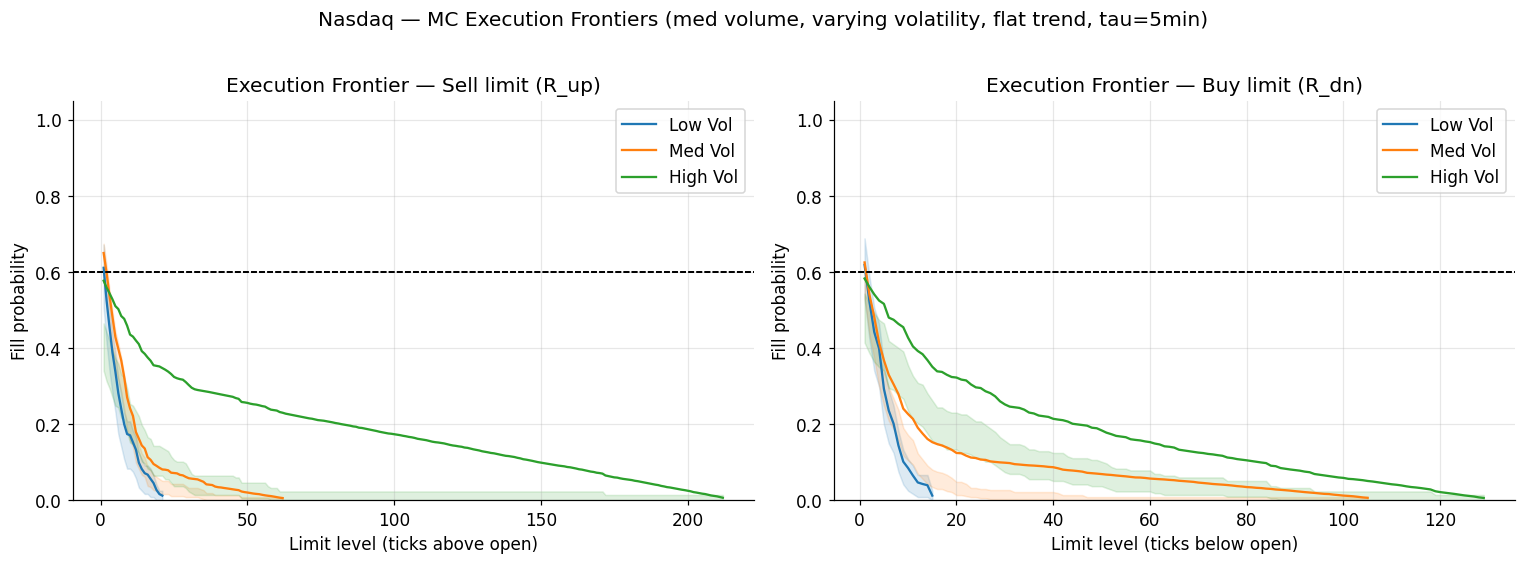

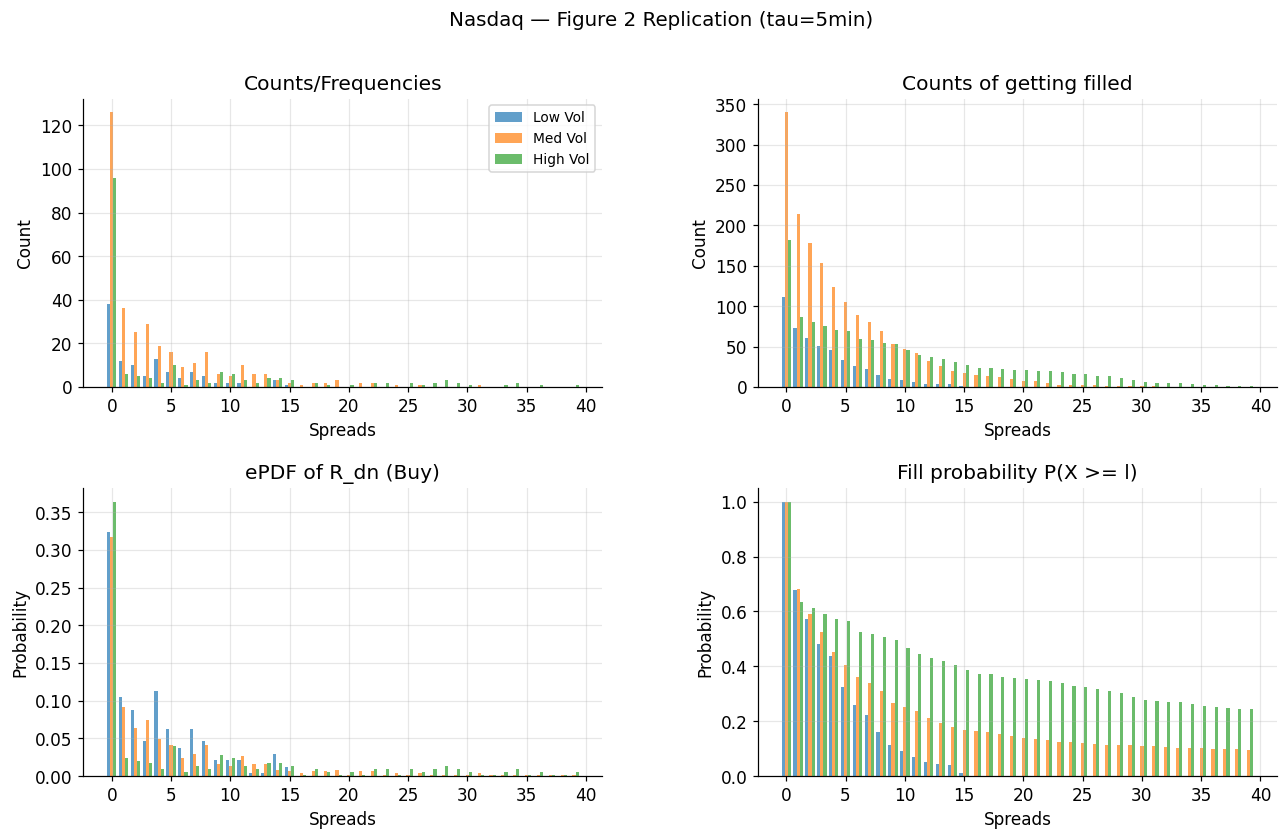

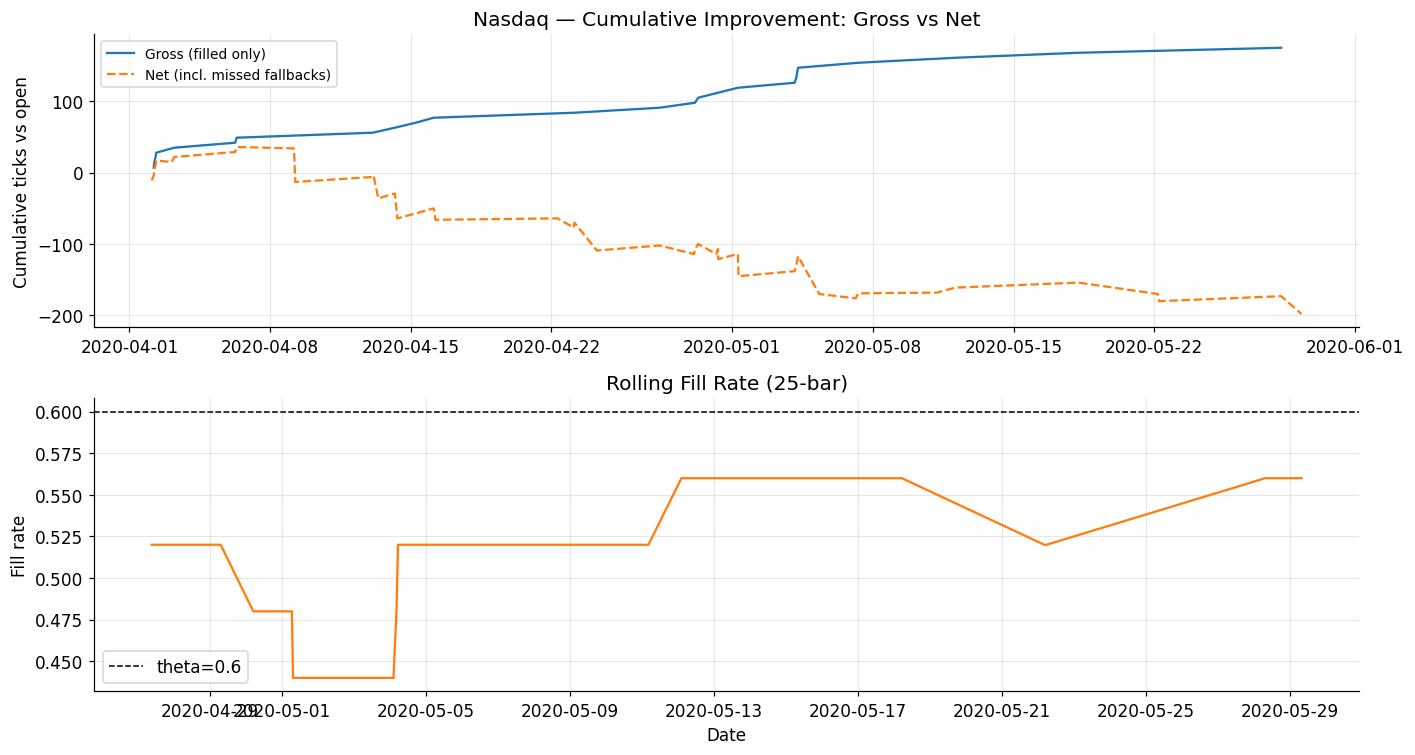

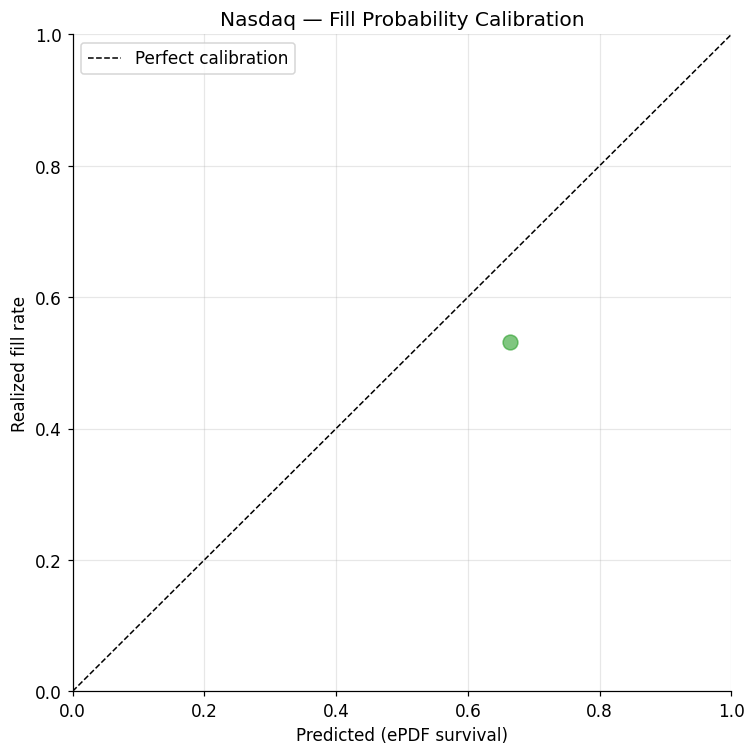

In [7]:
oe_plots.plot_execution_frontiers(res, cfg)
oe_plots.plot_figure2(res, cfg, direction='R_dn')
oe_plots.plot_cumulative_improvement(res, cfg)
oe_plots.plot_calibration(res, cfg)

## 3 &middot; Objective comparison

The core check: `net_of_miss` should hold up the honest `net_vs_market` column (realised ticks
including missed fills) relative to `expected_ticks`, typically by retreating to shallower levels or
market orders where deep limits lose money once misses are priced in.

In [8]:
rows = []
for obj in ['expected_ticks', 'cond_on_fill', 'net_of_miss']:
    r = oe.run_pipeline(PRIMARY_ASSET, cfg, registry, objective=obj)
    lv = r['optimal_levels']
    rows.append({
        'objective': obj,
        'market_cells': int(lv['sell_market'].sum() + lv['buy_market'].sum()),
        'max_ell': int(max(lv['sell_ell'].max(), lv['buy_ell'].max())),
        'limit_orders': r['limit_orders'],
        'fill_rate': round(r['fill_rate'], 3),
        'gross_edge': round(r['gross_edge'], 3),
        'net_vs_market': round(r['net_vs_market'], 3),
    })
print(pd.DataFrame(rows).set_index('objective').to_string())

                market_cells  max_ell  limit_orders  fill_rate  gross_edge  net_vs_market
objective                                                                                
expected_ticks             4       82           864      0.649       2.039        -10.140
cond_on_fill               4       82           864      0.649       2.039        -10.140
net_of_miss               53        7            47      0.532       3.723         -4.213


## 4 &middot; Sensitivity (tau x fill threshold)

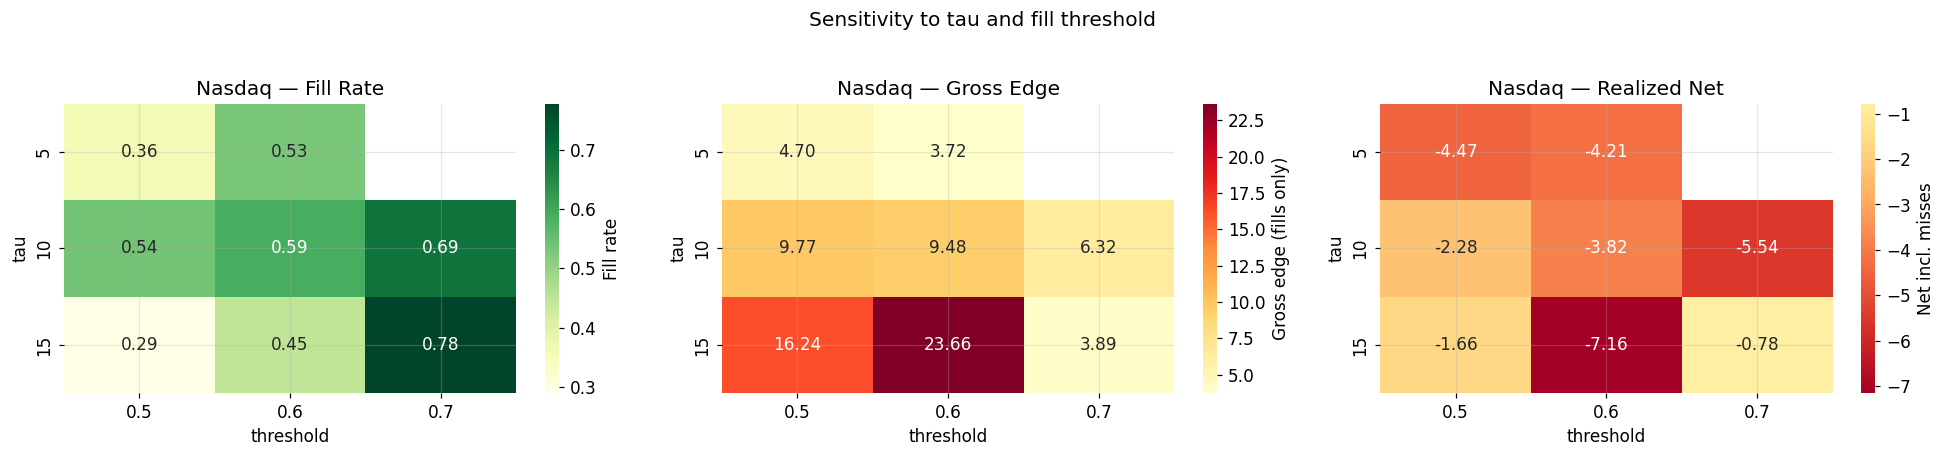

,tau,threshold,fill_rate,gross_edge,net_vs_market
0,5,0.5,0.362,4.702,-4.468
1,5,0.6,0.532,3.723,-4.213
2,5,0.7,NaN,NaN,NaN
3,10,0.5,0.540,9.766,-2.282
4,10,0.6,0.589,9.484,-3.823
5,10,0.7,0.691,6.317,-5.537
6,15,0.5,0.289,16.237,-1.658
7,15,0.6,0.447,23.658,-7.158
8,15,0.7,0.778,3.889,-0.778


In [9]:
TAU_GRID, THRESH_GRID = [5, 10, 15], [0.50, 0.60, 0.70]
rows = []
for tv in TAU_GRID:
    for th in THRESH_GRID:
        r = oe.run_pipeline(PRIMARY_ASSET, cfg, registry, tau=tv, fill_threshold=th)
        rows.append({'tau': tv, 'threshold': th,
                     'fill_rate': r['fill_rate'], 'gross_edge': r['gross_edge'],
                     'net_vs_market': r['net_vs_market']})
sens = pd.DataFrame(rows)
oe_plots.plot_sensitivity(sens, PRIMARY_ASSET)
sens.round(3)

## 5 &middot; Cross-asset comparison

Runs every discovered asset end to end. `net_vs_market` is the honest realised-ticks-vs-open column.

In [10]:
cross = oe.cross_asset_table(list(registry), cfg, registry)
print(cross.to_string())

             Tick  Limit trades Fill rate Impr|filled gross_edge net_vs_market
Asset                                                                         
Bunds       0.010             0       N/A         N/A        N/A           N/A
EuroStoxx   0.500             0       N/A         N/A        N/A           N/A
GBPUSD      0.010             0       N/A         N/A        N/A           N/A
Gold        0.100             0       N/A         N/A        N/A           N/A
HeatingOil  0.010             0       N/A         N/A        N/A           N/A
JPY         0.005             1     0.00%         N/A        N/A          0.00
Nasdaq      0.250            47    53.19%        7.00       3.72         -4.21
